# 01 - XAUUSD data ko dekhna aur verify karna

**Is notebook ka kaam:** jo data humne download aur process kiya, usko aankhon se check karna, strategy banane se pehle.

**Jupyter kaise chalate hain:**
- Har dabba ek **cell** hai. Cell select karke `Shift + Enter` dabao, toh wo chalega aur agle cell pe chale jaoge.
- Cells **upar se neeche order mein** chalao. Neeche wale cells upar wale variables use karte hain.
- Kuch gadbad ho jaye toh upar menu se **Restart** karo aur phir se sab cells chalao.
- Ye text wale cells **Markdown** hain (notes). Code wale cells Python hain.

## 1. Setup: libraries aur data ka path

`ROOT` wala loop project folder dhoondhta hai (jahan `data/processed` hai), taaki notebook kahin se bhi chalao, path sahi rahe.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project root dhoondo: jab tak data/processed na mile, ek folder upar jao
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
print("Data folder:", DATA)

def load(tf):
    """Ek timeframe ki Parquet file load karta hai."""
    return pd.read_parquet(DATA / f"XAUUSD_{tf}.parquet")

d1 = load("D1")
h1 = load("H1")
m5 = load("M5")
print(f"D1: {len(d1):,}  |  H1: {len(h1):,}  |  M5: {len(m5):,} candles")

Data folder: C:\Users\Prxj\ai-forex-trader\data\processed
D1: 2,770  |  H1: 63,487  |  M5: 760,923 candles


## 2. Data kaisa dikhta hai

- `head()` = pehli 5 rows, `tail()` = aakhri 5 rows
- `info()` = har column ka naam, type aur kitni values hain

In [2]:
d1.head()

,open,high,low,close,volume,spread,m5_count,close_time,trade_date
time,,,,,,,,,
2016-01-03 23:00:00+00:00,1062.341,1083.488,1061.729,1074.232,74.30,0.328279,276,2016-01-04 22:00:00+00:00,2016-01-04
2016-01-04 23:00:00+00:00,1073.550,1082.048,1072.629,1077.232,70.13,0.319692,276,2016-01-05 22:00:00+00:00,2016-01-05
2016-01-05 23:00:00+00:00,1076.969,1095.180,1074.928,1093.222,75.48,0.320290,276,2016-01-06 22:00:00+00:00,2016-01-06
2016-01-06 23:00:00+00:00,1093.410,1110.080,1091.350,1108.671,94.61,0.318587,276,2016-01-07 22:00:00+00:00,2016-01-07
2016-01-07 23:00:00+00:00,1108.269,1112.949,1092.229,1104.031,87.92,0.325580,276,2016-01-08 22:00:00+00:00,2016-01-08


In [3]:
d1.tail()

,open,high,low,close,volume,spread,m5_count,close_time,trade_date
time,,,,,,,,,
2026-09-20 22:00:00+00:00,4374.525,4383.165,4322.335,4342.585,27.10929,0.710688,276,2026-09-21 21:00:00+00:00,2026-09-21
2026-09-21 22:00:00+00:00,4343.085,4375.670,4291.245,4356.565,27.96193,0.744790,276,2026-09-22 21:00:00+00:00,2026-09-22
2026-09-22 22:00:00+00:00,4355.545,4369.185,4274.215,4287.255,27.45430,0.716909,276,2026-09-23 21:00:00+00:00,2026-09-23
2026-09-23 22:00:00+00:00,4288.115,4302.865,4243.925,4274.505,32.13656,0.743877,276,2026-09-24 21:00:00+00:00,2026-09-24
2026-09-24 22:00:00+00:00,4265.355,4309.385,4255.925,4308.045,11.80901,0.766133,150,2026-09-25 10:30:00+00:00,2026-09-25


In [4]:
d1.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2770 entries, 2016-01-03 23:00:00+00:00 to 2026-09-24 22:00:00+00:00
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   open        2770 non-null   float64            
 1   high        2770 non-null   float64            
 2   low         2770 non-null   float64            
 3   close       2770 non-null   float64            
 4   volume      2770 non-null   float64            
 5   spread      2770 non-null   float64            
 6   m5_count    2770 non-null   int64              
 7   close_time  2770 non-null   datetime64[us, UTC]
 8   trade_date  2770 non-null   datetime64[us]     
dtypes: datetime64[us, UTC](1), datetime64[us](1), float64(6), int64(1)
memory usage: 216.4 KB


## 3. Gold ka poora safar: Daily chart (2016 → aaj)

`plot()` pandas ka built-in chart hai, jo andar se matplotlib use karta hai. Log scale se % moves barabar dikhte hain (2016 ka +\$100 aur 2026 ka +\$100 alag weight rakhte hain).

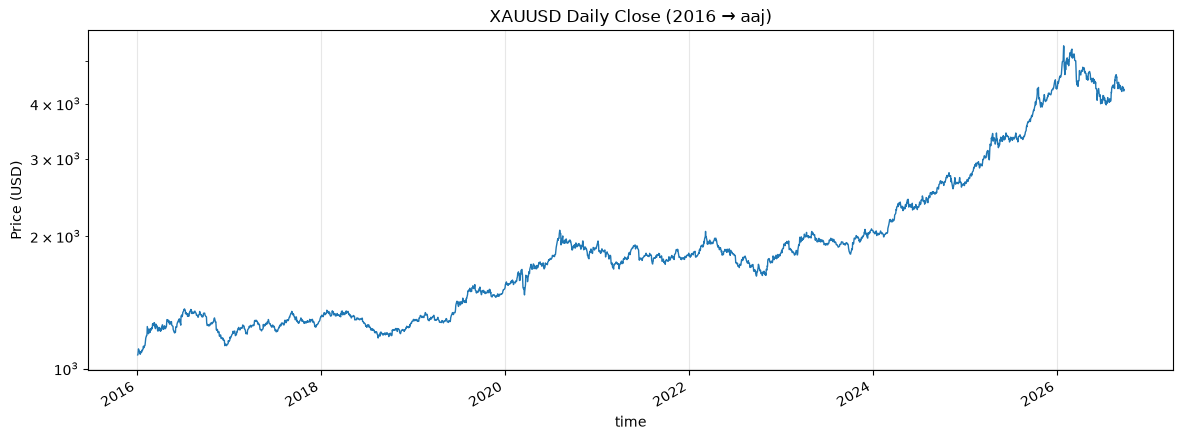

Pehla close: $1,074.23  (2016-01-03)
Aakhri close: $4,308.05  (2026-09-24)


In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
d1["close"].plot(ax=ax, linewidth=1)
ax.set_title("XAUUSD Daily Close (2016 → aaj)")
ax.set_ylabel("Price (USD)")
ax.set_yscale("log")
ax.grid(alpha=0.3)
plt.show()

print(f"Pehla close: ${d1['close'].iloc[0]:,.2f}  ({d1.index[0].date()})")
print(f"Aakhri close: ${d1['close'].iloc[-1]:,.2f}  ({d1.index[-1].date()})")

## 4. TradingView / MT5 se match karna

`time` = candle kab khuli (pichli shaam 6 PM NY), isliye wo ek din pehle ka dikhta hai. **`trade_date`** = asli trading din, jo TradingView dikhata hai. Compare hamesha `trade_date` se karna.

**Kya karna hai:** TradingView pe `XAUUSD` ka **Daily** chart kholo (OANDA ya FXCM wala), kisi ek din pe mouse le jao, aur O/H/L/C yahan se compare karo.
- Farak **\$1-3** tak normal hai. Har broker ka price feed thoda alag hota hai.
- Farak **bahut bada** hai (jaise \$20+), ya candles 1 din shift lag rahi hain, toh batao. Matlab kuch galat hai.

In [ ]:
check = d1.tail(10)
# round sirf price columns pe (date column pe round lagane se warning aati hai)
check[["trade_date", "open", "high", "low", "close", "m5_count"]].round({"open": 2, "high": 2, "low": 2, "close": 2})

## 5. Sessions label karna

Har M5 candle ko session ka naam denge. Timing **local time** mein hai, isliye DST apne aap handle hota hai:

| Session | Local time |
|---|---|
| Asian (Tokyo) | 9 AM - 6 PM Tokyo |
| London | 8 AM - 5 PM London |
| New York | 8 AM - 5 PM NY |

London aur NY dono khule hon toh **London+NY** (overlap). Koi bhi na khula ho toh **Off-hours** (ye mostly Sydney ka time hai).

`np.select` = conditions ki list, pehli jo true ho uska label lagao (upar wali condition ko priority milti hai).

In [7]:
def label_sessions(index):
    tokyo = np.asarray(index.tz_convert("Asia/Tokyo").hour)
    london = np.asarray(index.tz_convert("Europe/London").hour)
    ny = np.asarray(index.tz_convert("America/New_York").hour)

    in_asia = (tokyo >= 9) & (tokyo < 18)
    in_london = (london >= 8) & (london < 17)
    in_ny = (ny >= 8) & (ny < 17)

    return np.select(
        [in_london & in_ny, in_london, in_ny, in_asia],
        ["London+NY", "London", "New York", "Asian"],
        default="Off-hours",
    )

m5["session"] = label_sessions(m5.index)
m5["range"] = m5["high"] - m5["low"]   # ek M5 candle kitna hila (volatility)

SESSION_ORDER = ["Asian", "London", "London+NY", "New York", "Off-hours"]
m5["session"].value_counts().reindex(SESSION_ORDER)

session
Asian        246098
London       163977
London+NY    135080
New York     160532
Off-hours     55236
Name: count, dtype: int64

## 6. Spread aur volatility, session-wise

- **spread** = trade karne ka cost (USD mein, per ounce)
- **range** = ek M5 candle mein price kitna hila, yaani movement/opportunity
- **spread / range %** = cost vs movement. Ye jitna **kam**, utna achha. Matlab movement ke comparison mein cost chhota hai.

Pichle 2 saal ka data le rahe hain, kyunki purana spread aaj ke market pe apply nahi hota.

In [8]:
recent = m5[m5.index >= m5.index[-1] - pd.Timedelta(days=730)]

stats = recent.groupby("session").agg(
    avg_spread=("spread", "mean"),
    median_spread=("spread", "median"),
    avg_range=("range", "mean"),
    candles=("range", "size"),
).reindex(SESSION_ORDER)
stats["spread_vs_range_%"] = 100 * stats["avg_spread"] / stats["avg_range"]
stats.round(3)

,avg_spread,median_spread,avg_range,candles,spread_vs_range_%
session,,,,,
Asian,0.655,0.63,4.073,45934,16.083
London,0.593,0.56,3.809,30480,15.557
London+NY,0.624,0.58,6.018,25228,10.369
New York,0.610,0.57,3.541,29873,17.226
Off-hours,0.829,0.71,3.849,10253,21.536


## 7. Din ke kis ghante gold sabse zyada hilta hai (IST mein)

Har ghante ki average M5 range. IST mein isliye rakha hai taaki tumhe apne time ke hisaab se samajh aaye.

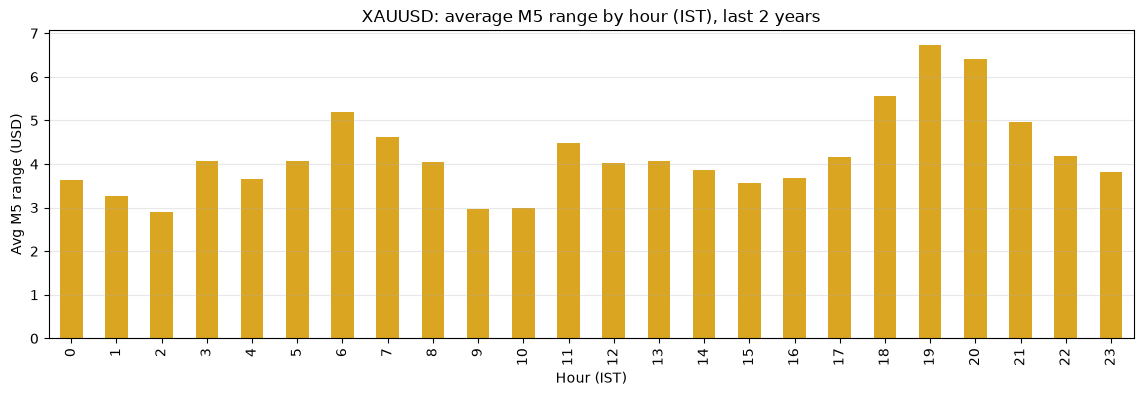

In [9]:
ist_hour = recent.index.tz_convert("Asia/Kolkata").hour
by_hour = recent.groupby(ist_hour).agg(avg_range=("range", "mean"), avg_spread=("spread", "mean"))

fig, ax = plt.subplots(figsize=(14, 4))
by_hour["avg_range"].plot(kind="bar", ax=ax, color="goldenrod")
ax.set_title("XAUUSD: average M5 range by hour (IST), last 2 years")
ax.set_xlabel("Hour (IST)")
ax.set_ylabel("Avg M5 range (USD)")
ax.grid(alpha=0.3, axis="y")
plt.show()

## 8. Spread saal dar saal

Gold ki price 2016 se kaafi badh gayi hai, toh spread (USD mein) bhi badha hoga. Isliye backtest mein **fixed spread nahi, har candle ka asli spread** use karenge.

In [10]:
yearly = m5.groupby(m5.index.year).agg(avg_spread=("spread", "mean"), avg_price=("close", "mean"))
yearly["spread_%_of_price"] = 100 * yearly["avg_spread"] / yearly["avg_price"]
yearly.round(4)

,avg_spread,avg_price,spread_%_of_price
time,,,
2016,0.3172,1249.7670,0.0254
2017,0.2493,1258.2821,0.0198
2018,0.2438,1268.9345,0.0192
2019,0.2964,1393.2915,0.0213
2020,0.5088,1771.8392,0.0287
2021,0.3599,1799.2725,0.0200
2022,0.3754,1801.3080,0.0208
2023,0.3366,1942.8051,0.0173
2024,0.3855,2388.4901,0.0161


## Observations (tum yahan likho)

Charts aur tables dekh ke apne notes likho. Jaise:
- Sabse sasta session kaunsa hai (spread vs range)?
- Kaunse IST ghante mein gold sabse zyada move karta hai?
- TradingView se match hua ya nahi?